Model Name                | RMSE       | MSE        | R² Score
--------------------------------------------------------------
KNN Regressor (k=5)       | 42.186     | 1779.63    | 0.8790  
Linear Regression         | 17.279     | 298.57     | 0.9797  
Ridge Regression (L2)     | 17.326     | 300.20     | 0.9796  
Lasso Regression (L1)     | 17.563     | 308.44     | 0.9790  
ElasticNet (L1+L2)        | 46.244     | 2138.53    | 0.8546  


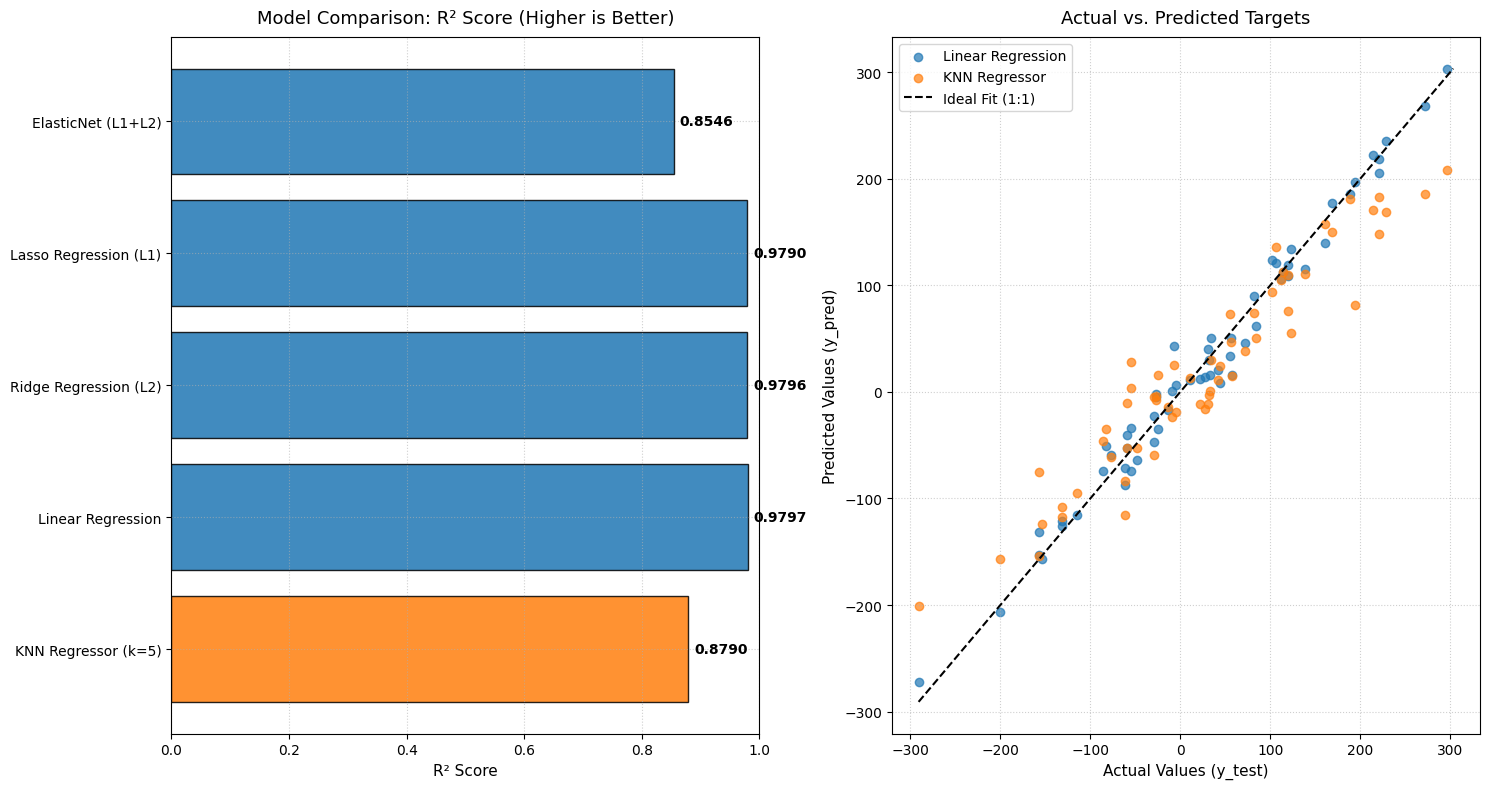

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

# ============================================================
# 1. Dataset Generation and Preprocessing
# ============================================================

# Generate continuous regression dataset (300 samples, 4 features)
X, y = make_regression(
    n_samples=300,
    n_features=4,
    n_informative=3,
    noise=20,
    random_state=42
)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature Scaling (Crucial for KNN; Linear models benefit for gradient stability)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 2. Model Initialization and Training
# ============================================================

models = {
    'KNN Regressor (k=5)': KNeighborsRegressor(n_neighbors=5, weights='distance'),
    'Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=1.0),
    'Lasso Regression (L1)': Lasso(alpha=1.0),
    'ElasticNet (L1+L2)': ElasticNet(alpha=1.0, l1_ratio=0.5)
}

results = {}

for name, model in models.items():
    # Fit model on scaled training data
    model.fit(X_train_scaled, y_train)

    # Predict on test data
    y_pred = model.predict(X_test_scaled)

    # Calculate performance metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results[name] = {
        'model': model,
        'predictions': y_pred,
        'mse': mse,
        'rmse': rmse,
        'r2': r2
    }


# ============================================================
# 3. Print Performance Summary Table
# ============================================================

print(f"{'Model Name':<25} | {'RMSE':<10} | {'MSE':<10} | {'R² Score':<8}")
print("-" * 62)
for name, metrics in results.items():
    print(f"{name:<25} | {metrics['rmse']:<10.3f} | {metrics['mse']:<10.2f} | {metrics['r2']:<8.4f}")


# ============================================================
# 4. Result Visualizations
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Plot 1: R² Score Performance Comparison
model_names = list(results.keys())
r2_scores = [results[m]['r2'] for m in model_names]

colors = ['#ff7f0e' if 'KNN' in m else '#1f77b4' for m in model_names]
bars = axes[0].barh(model_names, r2_scores, color=colors, edgecolor='black', alpha=0.85)

axes[0].set_title('Model Comparison: R² Score (Higher is Better)', fontsize=13, pad=10)
axes[0].set_xlabel('R² Score', fontsize=11)
axes[0].set_xlim(0, 1.0)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Annotate R² values on bars
for bar in bars:
    width = bar.get_width()
    axes[0].text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

# Plot 2: Actual vs. Predicted Values (KNN vs Linear Regression)
axes[1].scatter(y_test, results['Linear Regression']['predictions'],
                 alpha=0.7, color='#1f77b4', label='Linear Regression')
axes[1].scatter(y_test, results['KNN Regressor (k=5)']['predictions'],
                 alpha=0.7, color='#ff7f0e', label='KNN Regressor')

# Ideal 1:1 Line
min_val = min(y_test.min(), min(results['Linear Regression']['predictions']))
max_val = max(y_test.max(), max(results['Linear Regression']['predictions']))
axes[1].plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, label='Ideal Fit (1:1)')

axes[1].set_title('Actual vs. Predicted Targets', fontsize=13, pad=10)
axes[1].set_xlabel('Actual Values (y_test)', fontsize=11)
axes[1].set_ylabel('Predicted Values (y_pred)', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()